# Problem 3.6

Kepler's equation, which we mentioned in Section 2.2, defines the relationship between a planet's polar coordinates and the time elapsed from a given initial point and is stated as follows:

$$E - e \sin(E) = M,$$

where $M$ is the mean anomaly (a parameterization of time), $E$ is the eccentric anomaly (a parameterization of polar angle), and $e$ is the eccentricity of the elliptical orbit.

a. Use Newton's method to find $E$ when $e = 0.7$ and $M = \pi/2$.

b. Devise a fixed-point iteration to solve the same problem.

c. Compare the number of iterations and rate of convergence.

d. *Exploration:* Plot $E$ versus $M$ in the interval $[0, 2\pi]$ for $e = [0, 0.1, 0.5, 0.9]$ and interpret your results physically.

In [26]:
%load_ext autoreload
%autoreload 2
import numpy as np
import matplotlib.pyplot as plt
from scipy import optimize

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Approach

In [27]:
# a) use newton's method to solve Kepler's equation at e = 0.7 and M = pi/2
e_default = 0.7
M_default = np.pi/2

def residual(E, e=e_default, M=M_default):
    return E - e*np.sin(E) - M

def derrivative(E, e=e_default):
    return 1 - e*np.cos(E)

def solve_system_newton(E0, e=e_default, M=M_default, tol=1e-10, max_iter=100, table=False):
    E = E0
    history = []
    converged = False
    for i in range(max_iter):
        r = residual(E, e, M)
        dr = derrivative(E, e)
        history.append((i, E, r))
        if abs(r) < tol:
            converged = True
            break
        E -= r / dr
    if table:
        print(f"{'Iter':<5} {'E':<20} {'Residual':<20}")
        for i, E_i, r_i in history:
            print(f"{i:<5} {E_i:<20.10f} {r_i:<20.10e}")
        print(f"{'converged' if converged else 'NOT converged'} after {i} iterations")
    return E, history, converged

E, hist_newton, converged_newton = solve_system_newton(1.0, table=True)  # starting guess E0 = 1.0

Iter  E                    Residual            
0     1.0000000000         -1.1598260162e+00   
1     2.8653066581         1.1035612608e+00    
2     2.2058549131         7.1532726215e-02    
3     2.1553109396         7.2860012337e-04    
4     2.1547853513         8.0642775346e-08    
5     2.1547852931         8.8817841970e-16    
converged after 5 iterations


In [28]:
# b) use fixed point iteration to solve Kepler's equation at e = 0.7 and M = pi/2
def solve_system_fixed_point(E0, e=e_default, M=M_default, tol=1e-10, max_iter=100, table=False):
    E = E0
    history = []
    for i in range(max_iter):
        r = residual(E, e, M)
        history.append((i, E, r))
        if abs(r) < tol:
            break
        E = M + e * np.sin(E)
    if table:
        print(f"{'Iter':<5} {'E':<20} {'Residual':<20}")
        for i, E_i, r_i in history:
            print(f"{i:<5} {E_i:<20.10f} {r_i:<20.10e}")
        print(f"{'converged' if abs(r) < tol else 'NOT converged'} after {i} iterations")
    return E, history

E, hist_fp = solve_system_fixed_point(1.0, table=True)  # starting guess E0 = 1.0

Iter  E                    Residual            
0     1.0000000000         -1.1598260162e+00   
1     2.1598260162         6.9935977592e-03    
2     2.1528324184         -2.7054713239e-03   
3     2.1555378897         1.0432261464e-03    
4     2.1544946636         -4.0277312851e-04   
5     2.1548974367         1.5542902713e-04    
6     2.1547420077         -5.9990854258e-05   
7     2.1548019985         2.3152964548e-05    
8     2.1547788456         -8.9359405608e-06   
9     2.1547877815         3.4488099641e-06    
10    2.1547843327         -1.3310674425e-06   
11    2.1547856638         5.1372436172e-07    
12    2.1547851500         -1.9827160846e-07   
13    2.1547853483         7.6522789660e-08    
14    2.1547852718         -2.9533920642e-08   
15    2.1547853013         1.1398596955e-08    
16    2.1547852899         -4.3992813836e-09   
17    2.1547852943         1.6978998207e-09    
18    2.1547852926         -6.5530358917e-10   
19    2.1547852933         2.5291368999e

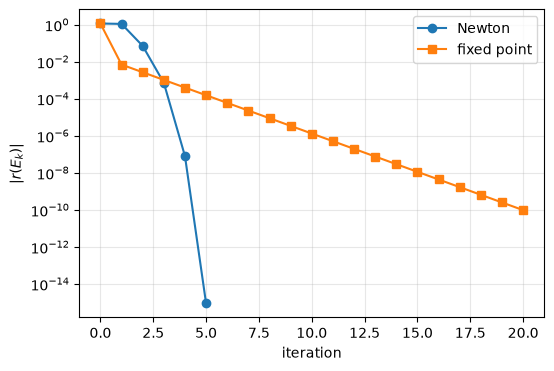

In [29]:
def abs_res(history):
    return np.abs([h[2] for h in history])

fig, ax = plt.subplots(figsize=(6, 4))
ax.semilogy(abs_res(hist_newton), "o-", label="Newton")
ax.semilogy(abs_res(hist_fp), "s-", label="fixed point")
ax.set_xlabel("iteration")
ax.set_ylabel("$|r(E_k)|$")
ax.grid(alpha=0.3, which="both")
ax.legend()
plt.show()

c) compare number of iterations  

for starting point = 1.0:  
newton = 5 iter  
fixed point = 20 iter  
fixed point iterations needs many more iterations to converge. form the plot we can see that the fixed point method converges linearly while newton converges quadraticaly (as stated in the book).  
newton:      asymptotic error constant gamma ~ 0.2 with p = 2 (quadratic)  
fixed point: asymptotic error constant gamma ~ 0.39 with p = 1 (linear)  

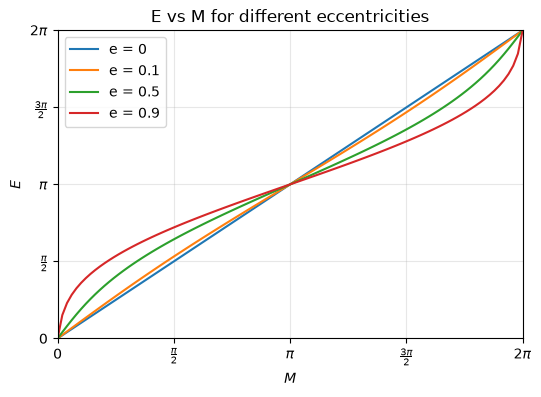

In [30]:
# d) plot E versus M in [0, 2pi] for e = [0, 0.1, 0.5, 0.9] and interpret the results

from fractions import Fraction
from matplotlib.ticker import MultipleLocator, FuncFormatter

def pi_label(x, _pos):
    frac = Fraction(x / np.pi).limit_denominator(12)   # x as a multiple of pi
    if frac == 0:
        return "0"
    n, d = frac.numerator, frac.denominator
    n_str = "" if n == 1 else str(n)
    if d == 1:
        return rf"${n_str}\pi$"
    return rf"$\frac{{{n_str}\pi}}{{{d}}}$"

e_values = [0, 0.1, 0.5, 0.9]
M_values = np.linspace(0, 2*np.pi, 100)

history_dict = {}
for e in e_values:
    E_values = []
    for M in M_values:
        E, _, converged = solve_system_newton(M, e=e, M=M, tol=1e-10, max_iter=100)
        if not converged:   # check if all runs converged, if not print a warning
            print(f"Warning: Newton's method did not converge for e={e}, M={M}")
        E_values.append(E)
    history_dict[e] = E_values

fig, ax = plt.subplots(figsize=(6, 4))
for e, E_values in history_dict.items():
    ax.plot(M_values, E_values, label=f"e = {e}")
ax.set_xlabel("$M$")
ax.set_ylabel("$E$")
ax.set_title("E vs M for different eccentricities")
ax.grid(alpha=0.3)

for axis in (ax.xaxis, ax.yaxis):
    axis.set_major_locator(MultipleLocator(np.pi / 2))
    axis.set_major_formatter(FuncFormatter(pi_label))
ax.set_xlim(0, 2 * np.pi)
ax.set_ylim(0, 2 * np.pi)

ax.legend()
plt.show()

d) interpretation of the results  
for e = 0 the orbit is a circle so the mean and excentric anomaly are idential because there is no excetricity.  
M is a parameterisation of time, E is a parameterisation of the polar angle (it is the angular distance to the pericenter). Around the closest point to the pericenter (periapis, E ~ 0, M ~ 0) the derrivative dE/dM = 1/(1 - e*cos(E)) is lager than 1. This means that the planet is moving faster than a uniform circular orbit. the opposite is true on the other side (apoapsis, E = pi). there it is slower.  
e increases the difference between E and M do aswell. so around periapsis the planet moves even faster and at apoapsis it moves even slower.

## Results

see above

## Interpretation

the fixed point method is simple but inefficient. it needs no derrivative but takes way longer to converge. this makes it useful when the calculation of the derrivative is slow and the calculation of the residual is fast. but then the finite difference method would make the newton solver viable again. so for this problem the newton sovler is the better choice. newton is prefered here since the analytic derrivative is available